# IND320 Project P3 — Data quality

Author: Robin Torjussen Egede  
[Streamlit app](https://ind320-hush.streamlit.app) · [Repository](https://github.com/Kunii/IND320-hush/)  

The four analysis functions are shared with the Streamlit app in
`src/utils/analysis.py`; this notebook is the executed hand-in.

### Disclaimer

I got severely ill the week leading up to the deadline (and still ill as of
2026-11-10 at 23:50). I was not in a capable state to do any real
"brain-activity", nor do the work at a sufficient level or to the quality I
wanted. Therefore this hand-in is rather lack-luster, and quite frankly
"AI-slop".

## Log

The implementation was AI-drafted; I directed the work and reviewed the code.

I started from the P2 repository and the P2 Streamlit app. The first step was
to convert the Canvas assignment page to Markdown and turn every bullet into a
checklist; that list became the structure of this notebook. I developed the
analysis as a plain Python script first, because the functions are easier to
iterate on outside a notebook, and then moved the documented version into this
notebook.

The largest data task was joining the Magasinstatistikk areas to the NVE Atlas
layers. The electricity areas are the `Budomraade` layer (`NO 1`–`NO 5`); the
assignment's precipitation areas are the five NVE administrative regions
(`RS`, `RØ`, `RV`, `RM`, `RN`), grouped as East = RS + RØ, West = RV and
North = RM + RN. The Atlas download page was intermittently unavailable, so I
first used the public ArcGIS REST endpoint for the same layers. Using the
official shapefiles then exposed a bug: `NVE_Region.dbf` has no `.cpg`, so GDAL
read it as Latin-1, `REGION` came back as `RÃ˜` for Region Øst, and
`East = RS + RØ` matched Region Sør alone — 74 686 km² instead of 138 366 km².
The loader now reads UTF-8 and rejects a group with a missing code. Sampling uses geopandas' `sample_points`, which handles
MultiPolygons and holes correctly.

The ERA5 download was the most demanding part. Open-meteo accepts several
coordinates per request, but the free tier weights requests by locations and
time span. The downloader batches eight locations per request, pauses between requests
and retries on 429/5xx. The hourly response is kept for the NO3 2024 retrieval and reduced to
daily area means for the SPC/LOF analysis, so 1000 locations do not
accumulate millions of rows in the analysis.

For the analyses, STL, a spectrogram, DCT-based SPC and LOF were drafted as
functions with parameters and sensible defaults. The SPC limits follow the
seasonal baseline from the low-pass part of the DCT, with a robust MAD-based
sigma; the SATV is not plotted. The default is 12 cycles/year and ±3σ, the
conventional control limit; the ±2σ sensitivity is reported in §6. LOF uses
the 1% contamination required by the task and compares each day with its
neighbours in time.

Testing was done with a small self-test module and with the executed cells in
this notebook. The tests check that STL reconstructs the series, that the
spectrogram shapes are consistent, that the SATV removes a constant/annual
signal, that an injected spike is flagged by SPC, and that LOF returns about
the requested proportion.

On the Streamlit side, the P2 app already provided the area selectors, the
cached NVE loader and the MongoDB page. The two CA3 pages were built on that
structure: a local selector that follows the Magasinstatistikk choice, a
weather step that reads the precomputed ERA5 caches, and two tabbed pages
(STL | Spectrogram and SPC | LOF).

## AI usage

This notebook was produced with an AI coding agent; no code was written by hand.

**Why:** I was ill and not in a capable state to do the work myself.

In [1]:
%matplotlib inline

In [2]:
from __future__ import annotations

import io
import os
import time
from pathlib import Path
from typing import Any, Iterable, Sequence

# Timestamps are handled in UTC everywhere (same convention as the P2 notebook).
os.environ.setdefault("TZ", "UTC")

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sys

# Locate the repository root by walking upwards until pyproject.toml is
# found. This keeps the paths valid whether the notebook is run from
# notebooks/CA3 or from the repository root.
REPO_ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "pyproject.toml").exists()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from IPython.display import display

from src.utils.magasin import (
    PARQUET_CACHE,
    REQUIRED_COLUMNS,
    fetch_magasinstatistikk,
)

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------

CACHE_DIR = REPO_ROOT / "data" / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Magasinstatistikk area used for the STL and spectrogram analysis.
# NO / area 0 is the whole-country aggregate, which gives one complete series.
MAGASIN_AREA_TYPE = "NO"
MAGASIN_AREA_NUMBER = 0
MAGASIN_MEASUREMENT = "water_level"  # "fyllingsgrad" in the raw NVE response

# NVE Atlas layers. ``layer_name`` is the ArcGIS layer name: the numeric id in
# ``url`` is only a fallback, because NVE republishes services and ids move
# (Administrasjon2 has already reordered its layers once). ``shapefile`` lists
# the local candidates in priority order: the committed copy under
# data/shapefiles/atlas_nve is the published dependency, the gitignored raw
# dump under data/atlas_nve is the same file before it was copied.
NVE_LAYERS = {
    "electricity": {
        "url": "https://kart.nve.no/enterprise/rest/services/Nettomraader/MapServer/0",
        "layer_name": "Budomraade",
        "field": "budomr",
        "shapefile": (
            "data/shapefiles/atlas_nve/Budområder/Budområder.shp",
            "data/atlas_nve/Budområder/Budområder.shp",
        ),
    },
    "precipitation": {
        "url": (
            "https://kart.nve.no/enterprise/rest/services/"
            "Mapservices/Administrasjon2/MapServer/0"
        ),
        "layer_name": "NVE_Region",
        "field": "REGION",
        "shapefile": (
            "data/shapefiles/atlas_nve/NVE_Region/NVE_Region.shp",
            "data/atlas_nve/NVE_Region/NVE_Region.shp",
        ),
    },
}

# Electricity price areas (Magasinstatistikk EL 1-5).
ELECTRICITY_AREAS = ("NO1", "NO2", "NO3", "NO4", "NO5")

# NVE administrative regions grouped the way the assignment describes.
PRECIPITATION_GROUPS = {
    "East": ("RS", "RØ"),
    "West": ("RV",),
    "North": ("RM", "RN"),
}

# Magasinstatistikk VASS areas -> the precipitation groups above.
VASS_TO_PRECIPITATION = {
    1: "East",
    2: "West",
    3: "North",
}

# Which area is downloaded and analysed here.
WEATHER_AREA_KIND = "electricity"  # "electricity" or "precipitation"
WEATHER_AREA_NAMES = ("NO3",)  # e.g. ("NO3",) or ("East", "West", "North")
WEATHER_YEAR = 2024

POINTS_PER_REGION = 1000
RANDOM_SEED = 42
ERA5_VARIABLES = ("temperature_2m", "precipitation")

# Hourly ERA5 values are reduced to daily values while downloading so that
# 1000 locations do not accumulate millions of rows in memory.
DAILY_AGGREGATION = {"temperature_2m": "mean", "precipitation": "sum"}

API_BATCH_SIZE = 8  # coordinates per request (open-meteo weighs locations x variables)
API_PAUSE_SECONDS = 4.0
API_MAX_ATTEMPTS = 6
API_BACKOFF_SECONDS = 5.0

# Analysis parameters, all with sensible defaults as required by the task.
# The DCT cut-off is expressed in cycles per year: 12 removes variations
# slower than about one month, leaving the seasonal baseline. 3 sigma is the
# conventional SPC control limit; the 2 sigma sensitivity is reported in §6.
SPC_CUTOFF_CYCLES_PER_YEAR = 12.0
SPC_STD_DEVIATIONS = 3.0
LOF_CONTAMINATION = 0.01  # proportion of outliers (1%)
STL_PERIOD = 52  # weekly data -> yearly season
STL_SEASONAL = 13
STL_TREND = 101
STL_ROBUST = True
SPECTROGRAM_WINDOW = 52
SPECTROGRAM_OVERLAP = 26

# Caching switches.
REFRESH_NVE = False
REFRESH_AREAS = False
REFRESH_WEATHER = False

ERA5_URL = "https://archive-api.open-meteo.com/v1/archive"

2026-11-16 19:29:12.673 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-16 19:29:12.674 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-16 19:29:12.674 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


In [3]:
# The analysis functions are imported from the module shared with the app.
from src.utils.analysis import (
    lof_outliers,
    spectrogram_analysis,
    spc_outliers,
    stl_analysis,
)

In [4]:
# Print the versions and paths used by this run so the output is reproducible.
import shapely

print(f"Repository root: {REPO_ROOT}")
print(f"pandas {pd.__version__} | geopandas {gpd.__version__} | shapely {shapely.__version__}")
print(f"magasinstatistikk cache: {PARQUET_CACHE.relative_to(REPO_ROOT)}")
print(f"weather cache directory: {CACHE_DIR.relative_to(REPO_ROOT)}")

Repository root: /mnt/nvme_storage/projects/NMBU/IND320
pandas 3.0.3 | geopandas 1.2.0 | shapely 2.2.0
magasinstatistikk cache: data/cache/magasinstatistikk.parquet
weather cache directory: data/cache


## 1. Reservoir filling data

The NVE Magasinstatistikk endpoint returns one observation per ISO week for
each area type (`EL`, `NO`, `VASS`). The analysis uses the whole-country
aggregate (`NO`, area `0`) because it is one complete series. `filling_series`
selects the area, removes duplicate weeks, resamples to a regular Monday index
and interpolates gaps, which STL and the spectrogram require.

In [5]:
def require_columns(frame: pd.DataFrame, columns: Iterable[str], name: str) -> None:
    """Raise a readable error when a frame is missing expected columns."""
    missing = sorted(set(columns) - set(frame.columns))
    if missing:
        raise ValueError(f"{name} is missing columns: {', '.join(missing)}")

In [6]:
def cache_path(name: str) -> Path:
    """Return a parquet cache path under ``data/cache``."""
    return CACHE_DIR / f"{name}.parquet"

In [7]:
def normalise_code(value: Any) -> str:
    """Normalise an area code so that "NO 3", "no3" and "NO3" all compare equal."""
    return str(value).replace(" ", "").strip().upper()

In [8]:
def load_magasinstatistikk(refresh: bool = REFRESH_NVE) -> pd.DataFrame:
    """Load the NVE data from the shared parquet cache or fetch it again."""
    if PARQUET_CACHE.exists() and not refresh:
        frame = pd.read_parquet(PARQUET_CACHE)
        require_columns(frame, REQUIRED_COLUMNS, "NVE cache")
        print(f"Loaded {len(frame):,} rows from {PARQUET_CACHE.name}")
        return frame.sort_values("date").reset_index(drop=True)

    frame = fetch_magasinstatistikk()
    PARQUET_CACHE.parent.mkdir(parents=True, exist_ok=True)
    frame.to_parquet(PARQUET_CACHE, index=False)
    print(f"Fetched and cached {len(frame):,} rows")
    return frame

In [9]:
def filling_series(
    df: pd.DataFrame,
    area_type: str = MAGASIN_AREA_TYPE,
    area_number: int = MAGASIN_AREA_NUMBER,
    measurement: str = MAGASIN_MEASUREMENT,
) -> pd.Series:
    """
    Return one weekly reservoir-filling series with a DatetimeIndex.

    NVE publishes one observation per ISO week, so the series is already
    regular. Duplicate weeks are averaged and gaps are interpolated, because
    STL and the spectrogram both require an evenly spaced signal.
    """
    mask = (df["area_type"] == area_type) & (df["area_number"] == area_number)
    series = (
        df.loc[mask, ["date", measurement]]
        .dropna()
        .set_index("date")[measurement]
        .sort_index()
    )
    series = series[~series.index.duplicated(keep="first")]
    series = series.resample("W-MON").mean().interpolate("time")
    series.name = f"{area_type}{area_number}_{measurement}"
    return series

Loaded 14,949 rows from magasinstatistikk.parquet


,date,area_type,area_number,iso_year,iso_week,water_level,twh_cap,twh_fill,next_publication_date,water_level_prev_week,water_level_change
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,NaT,0.614288,0.002160
1,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,NaT,0.756482,-0.121041
2,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,NaT,0.777604,-0.146657
3,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,NaT,0.596027,0.006349
4,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,NaT,0.583705,0.033869


Filling series: 1661 weekly observations, 1995-01-09 to 2026-11-02
Missing values after resampling: 0


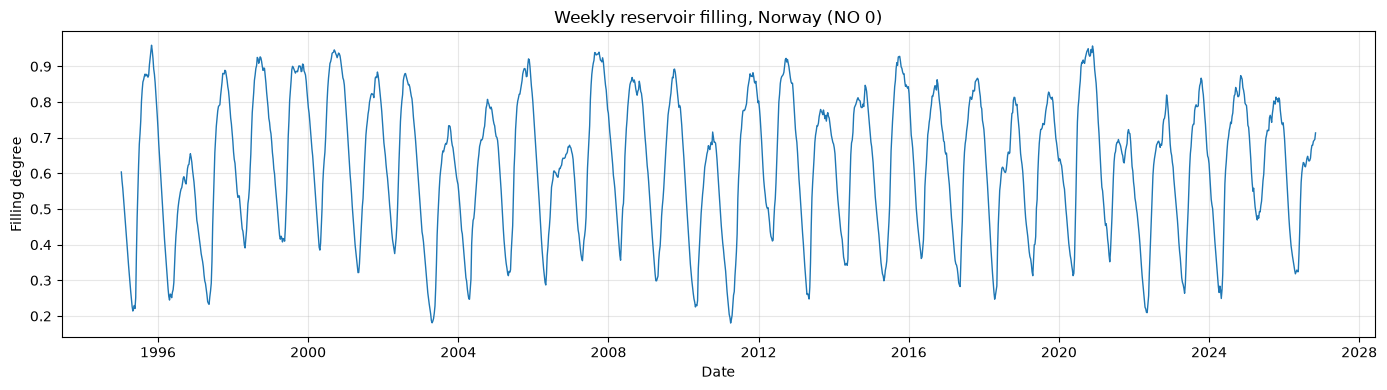

In [10]:
# Load the NVE history and build the weekly filling series used by STL and
# the spectrogram. The first run may fetch the API; later runs use the cache.
df_mag = load_magasinstatistikk()
display(df_mag.head())

filling = filling_series(df_mag, area_type="NO", area_number=0)
print(f"Filling series: {len(filling)} weekly observations, "
      f"{filling.index.min().date()} to {filling.index.max().date()}")
print(f"Missing values after resampling: {int(filling.isna().sum())}")

# Plot the series so the annual cycle and the multi-year variations are visible.
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(filling.index, filling, linewidth=1.0)
ax.set_title("Weekly reservoir filling, Norway (NO 0)")
ax.set_xlabel("Date")
ax.set_ylabel("Filling degree")
ax.grid(True, alpha=0.3)
fig.tight_layout()

## 2. Seasonal-Trend decomposition using LOESS (STL)

STL splits the weekly filling series into trend, seasonal and residual
components. `period=52` is one year of weekly data, `seasonal=13` controls the
seasonal smoother, `trend=101` the trend smoother, and `robust=True`
downweights unusual weeks. The function returns both the figure and the
`STLResult` so the components can be inspected.

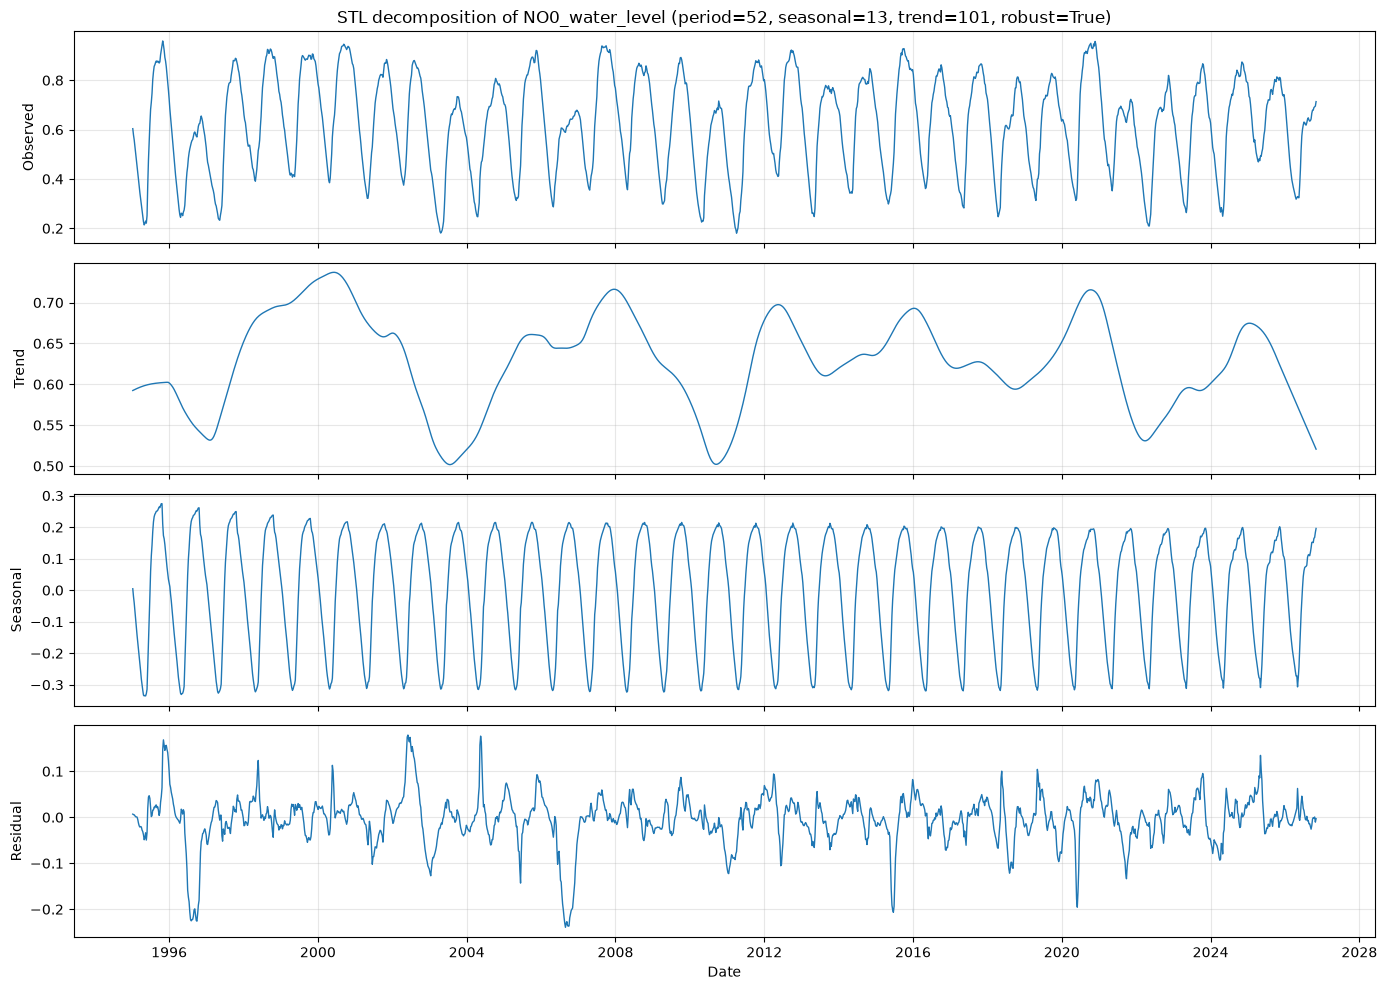

STL period=52 weeks, seasonal=13, trend=101, robust=True
Trend range: 0.502 to 0.737
Seasonal amplitude: 0.610
Residual standard deviation: 0.055


In [11]:
# STL with the defaults from the configuration section.
stl_fig, stl_result = stl_analysis(filling)
display(stl_fig)
plt.close(stl_fig)

print(f"STL period={STL_PERIOD} weeks, seasonal={STL_SEASONAL}, "
      f"trend={STL_TREND}, robust={STL_ROBUST}")
print(f"Trend range: {stl_result.trend.min():.3f} to {stl_result.trend.max():.3f}")
print(f"Seasonal amplitude: {stl_result.seasonal.max() - stl_result.seasonal.min():.3f}")
print(f"Residual standard deviation: {stl_result.resid.std():.3f}")

**Findings.** The trend moves between about 0.50 and 0.74 over the thirty
years, while the annual cycle stays stable. The largest residuals are in late
summer and autumn 2006, a dry period, and at the very end of the series, where
LOESS has data on one side only.

## 3. Spectrogram

The spectrogram uses a 52-week window with 26 weeks of overlap. Frequencies
are in cycles per week, so the annual cycle is the first non-zero bin at
1/52 ≈ 0.019 cycles/week. The plot zooms to 0–0.1 cycles/week because almost
all of the hydrological signal is below that; pass `max_frequency=None` for
the full 0–0.5 range.

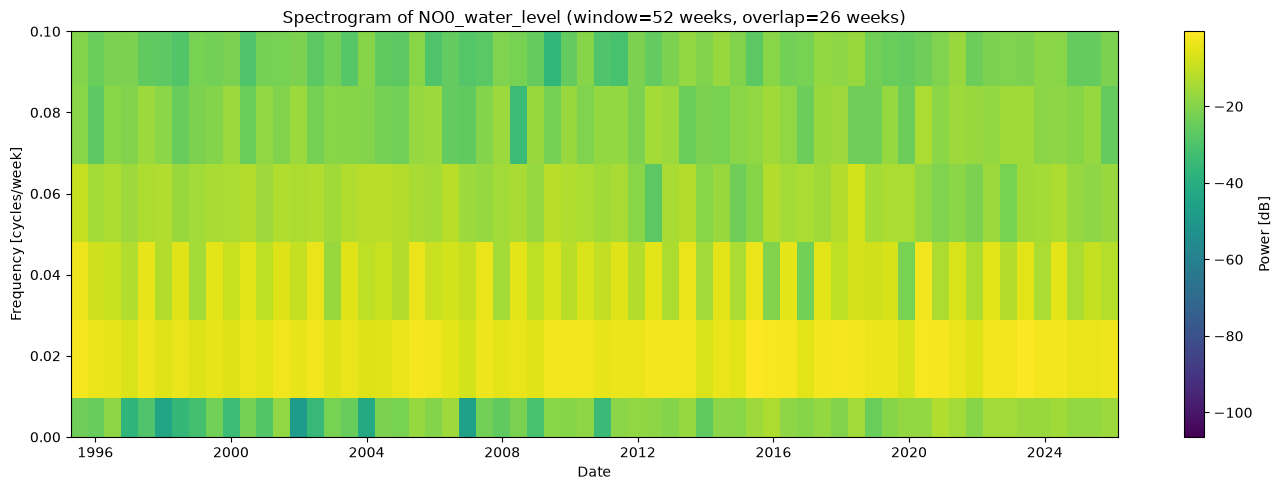

Frequency resolution: 0.0192 cycles/week
Annual cycle expected at 0.0192 cycles/week
Spectrogram shape: (27, 62) (frequency bins x segments)


In [12]:
# Spectrogram of the same filling series.
spec_fig, spec_freqs, spec_times, spec_power = spectrogram_analysis(filling)
display(spec_fig)
plt.close(spec_fig)

annual = 1 / STL_PERIOD
print(f"Frequency resolution: {spec_freqs[1]:.4f} cycles/week")
print(f"Annual cycle expected at {annual:.4f} cycles/week")
print(f"Spectrogram shape: {spec_power.shape} (frequency bins x segments)")

**Findings.** The annual band at about 0.019 cycles/week dominates the whole
period; the weaker band at twice that frequency is the semi-annual harmonic.
The 0–0.1 cycles/week window makes both visible.

## 4. NVE Atlas areas and 1000-point sampling

The electricity areas are the `Budomraade` layer (`budomr` = `NO 1`…`NO 5`).
The assignment's precipitation areas are the five NVE administrative regions
(`RV`, `RM`, `RN`, `RØ`, `RS`), grouped as East = RS + RØ, West = RV and
North = RM + RN. Both layers are in EPSG:25833 and are reprojected to WGS84.

The shapefiles downloaded from <https://atlas.nve.no> are the primary source,
committed under `data/shapefiles/atlas_nve/` (`Budområder/` and `NVE_Region/`)
so the notebook runs from a fresh clone. They are the
same data the ArcGIS service serves, but pinned: the notebook stays
reproducible when `nedlasting.nve.no` is down or when NVE republishes a layer
(the service ids have already moved once). The REST GeoJSON export remains the
fallback when the shapefiles are absent, and it is what you diff against when a
boundary is suspected to have changed.

`NVE_Region.dbf` ships without a `.cpg` file, so GDAL assumes Latin-1 and
`REGION` for Region Øst arrives as `RÃ˜`. Read as UTF-8 — otherwise `East =
RS + RØ` silently matches Region Sør alone.

### Coordinate reference systems

Three CRSs appear in this notebook, each at a fixed boundary:

| CRS | Where | Why |
|---|---|---|
| EPSG:25833 (ETRS89 / UTM 33N) | the shapefiles, the ArcGIS layers and the area checks | NVE's native CRS, in metres |
| EPSG:4326 (WGS84 lon/lat) | `read_area_shapefile`, the GeoJSON fallback and every open-meteo request | what GeoJSON and the weather API speak |
| none | the Streamlit pages | they read area-keyed aggregates, no coordinates |

`sample_area_points` draws **uniformly in EPSG:4326** — uniform per square
degree, not per km². That is not neutral at these latitudes: NO3 receives about
3.3× more points per km² in its northern half than in its southern half, so the
area mean leans slightly north and cold. The app's precomputed series samples in
EPSG:3035 (equal-area, land-clipped), so the two are deliberately different
estimators. `docs/CA3/crs.md` records the measurements and the rules.

Geopandas' `sample_points` respects MultiPolygons and holes, so the assignment's
1000 locations per region land where they should within the sampling space; the
table below checks every region.

In [13]:
def read_area_shapefile(path: Path) -> gpd.GeoDataFrame:
    """
    Read an NVE Atlas area shapefile and return it in WGS84.

    The file is stored as EPSG:25833 (ETRS89 / UTM 33N, metres); it is
    reprojected to EPSG:4326 because that is the space the rest of the notebook
    works in (sampling, open-meteo, figures). Keep the original file's CRS in
    mind for anything metric: an area computed here is in square degrees and
    meaningless — reproject to 25833 (source, conformal) or 3035 (equal-area).

    The official ``NVE_Region`` download has no ``.cpg`` sidecar, so GDAL
    assumes ISO-8859-1 and ``REGION`` for Region Øst arrives as ``'RÃ\x98'``
    instead of ``'RØ'``. That is not cosmetic: the East group is
    ``("RS", "RØ")``, so a mismatched code silently drops a whole region.
    Read as UTF-8 first and fall back only if the file really is latin-1.
    """
    try:
        frame = gpd.read_file(path, encoding="utf-8")
    except UnicodeDecodeError:
        frame = gpd.read_file(path)
    return frame.to_crs("EPSG:4326")


def local_area_shapefile(layer: dict[str, Any]) -> Path | None:
    """Return the first existing shapefile candidate for one layer."""
    for candidate in layer["shapefile"]:
        path = REPO_ROOT / candidate
        if path.exists():
            return path
    return None


def resolve_service_layer_id(url: str, layer_name: str) -> int:
    """
    Look up an ArcGIS layer id by name, falling back to the pinned id.

    NVE republishes services, so a hard-coded id can start pointing at a
    different layer. The name is stable where the id is not.
    """
    service, pinned = url.rsplit("/", 1)
    try:
        response = requests.get(f"{service}/?f=json", timeout=60)
        response.raise_for_status()
        layers = response.json().get("layers", [])
    except (requests.RequestException, ValueError):
        return int(pinned)
    for entry in layers:
        if entry.get("name") == layer_name:
            return int(entry["id"])
    return int(pinned)


def download_area_layer(
    kind: str, refresh: bool = REFRESH_AREAS
) -> gpd.GeoDataFrame:
    """
    Load one NVE Atlas polygon layer in WGS84.

    Priority: a local shapefile downloaded from atlas.nve.no, then the cached
    GeoJSON export of the same ArcGIS layer, then a fresh download. Both routes
    address the same source layer, so the numbers agree either way; the local
    file only avoids depending on the service at run time.

    Returns EPSG:4326 regardless of route — the shapefile is EPSG:25833 on disk
    and the GeoJSON is requested with ``outSR=4326``, so both are reprojected to
    the same space here. See the module docstring for why 4326 and when to use
    25833 or 3035 instead.
    """
    if kind not in NVE_LAYERS:
        raise KeyError(f"Unknown area kind {kind!r}; use {sorted(NVE_LAYERS)}")

    layer = NVE_LAYERS[kind]
    local = local_area_shapefile(layer)
    if local is not None:
        print(f"Reading {local.relative_to(REPO_ROOT)}")
        return read_area_shapefile(local)

    cache = CACHE_DIR / f"{kind}_areas.geojson"
    if not cache.exists() or refresh:
        layer_id = resolve_service_layer_id(layer["url"], layer["layer_name"])
        service = layer["url"].rsplit("/", 1)[0]
        response = requests.get(
            f"{service}/{layer_id}/query",
            params={
                "where": "1=1",
                "outFields": "*",
                "outSR": "4326",
                "f": "geojson",
            },
            timeout=180,
        )
        response.raise_for_status()
        cache.write_text(response.text, encoding="utf-8")
        print(f"Downloaded {kind} areas from {layer['layer_name']} -> {cache.name}")

    return gpd.read_file(io.StringIO(cache.read_text(encoding="utf-8"))).to_crs(
        "EPSG:4326"
    )

In [14]:
def area_codes(kind: str) -> dict[str, tuple[str, ...]]:
    """
    Return the selectable areas for a layer.

    Electricity areas map one-to-one to the NO codes; the precipitation layer
    exposes the NVE regions and groups them into East/West/North.
    """
    if kind == "electricity":
        return {code: (code,) for code in ELECTRICITY_AREAS}
    if kind == "precipitation":
        return dict(PRECIPITATION_GROUPS)
    raise KeyError(f"Unknown area kind {kind!r}")

In [15]:
def select_area_geometry(
    areas: gpd.GeoDataFrame, kind: str, name: str
) -> Any:
    """
    Return the union of every polygon belonging to one area name.

    Grouped areas (East = RS + RØ, North = RM + RN) are merged so that a single
    sampling step covers the whole group.
    """
    codes = area_codes(kind)
    if name not in codes:
        raise KeyError(f"{name!r} is not an area of kind {kind!r}: {sorted(codes)}")

    field = NVE_LAYERS[kind]["field"]
    wanted = {normalise_code(code) for code in codes[name]}
    available = {normalise_code(value) for value in areas[field].dropna().unique()}
    missing = sorted(wanted - available)
    if missing:
        raise KeyError(
            f"{kind!r} has no rows for {missing}; available codes: "
            f"{sorted(available)}. A missing code usually means the file was "
            "read with the wrong encoding ('RÃ\\x98' instead of 'RØ')."
        )

    matches = areas[field].map(normalise_code).isin(wanted)

    geometry = areas.loc[matches, "geometry"].union_all()
    if not geometry.is_valid:
        geometry = geometry.buffer(0)
    return geometry

In [16]:
def sample_area_points(
    geometry: Any,
    count: int = POINTS_PER_REGION,
    seed: int = RANDOM_SEED,
) -> pd.DataFrame:
    """
    Draw ``count`` uniformly distributed points inside a polygon.

    The draw happens in EPSG:4326, so "uniform" means uniform per square
    degree, not per km². At Norwegian latitudes a square degree covers less
    than half as much ground at 71°N as at 60°N, so the sample is denser per
    km² in the north: measured on NO3, the northern half receives about 3.3x
    the points per km² of the southern half. That is a small north-and-cold
    bias in the area mean. ``precompute_weather.py`` avoids it by sampling in
    EPSG:3035 (equal-area) and clipping to land; changing this function to do
    the same would change every reported coordinate, so the notebook keeps the
    degree sampler and documents it. ``docs/CA3/crs.md`` has the numbers.

    Returns a DataFrame with WGS84 ``lon`` and ``lat`` columns, ready for
    open-meteo, which takes EPSG:4326 by definition.
    """
    if count < 1:
        raise ValueError("count must be at least 1")

    points = gpd.GeoSeries([geometry], crs="EPSG:4326").sample_points(
        count, rng=seed
    )
    multipoint = points.iloc[0]
    coordinates = pd.DataFrame(
        {"lon": [p.x for p in multipoint.geoms], "lat": [p.y for p in multipoint.geoms]}
    )
    if len(coordinates) != count:
        raise RuntimeError(
            f"Expected {count} sampled points, got {len(coordinates)}"
        )
    return coordinates

In [17]:
def area_sample_name(kind: str, name: str, count: int = POINTS_PER_REGION) -> str:
    """Return the cache name for one area's sampled locations."""
    return f"points_{kind}_{name}_{count}"

In [18]:
# Load both NVE Atlas layers. The committed shapefiles under
# data/shapefiles/atlas_nve/ are used when present; otherwise the GeoJSON is
# downloaded from the ArcGIS REST endpoint (resolving the layer by name) and
# cached under data/cache.
electricity_layer = download_area_layer("electricity")
precipitation_layer = download_area_layer("precipitation")

print(f"Electricity areas: {len(electricity_layer)} features")
print(f"Precipitation regions: {len(precipitation_layer)} features")
display(precipitation_layer[["REGION", "REGIONNAVN"]])
display(electricity_layer[["budomr"]].sort_values("budomr"))

Reading data/shapefiles/atlas_nve/Budområder/Budområder.shp
Reading data/shapefiles/atlas_nve/NVE_Region/NVE_Region.shp
Electricity areas: 5 features
Precipitation regions: 5 features


,REGION,REGIONNAVN
0,RS,Region Sør
1,RV,Region Vest
2,RØ,Region Øst
3,RM,Region Midt-Norge
4,RN,Region Nord


,budomr
4,NO 1
3,NO 2
1,NO 3
0,NO 4
2,NO 5


In [19]:
# Sample 1000 locations in every region and summarise the result.
# This is local geometry work; it does not call the weather API.
sampling_rows = []
for kind, names in (
    ("electricity", ELECTRICITY_AREAS),
    ("precipitation", tuple(PRECIPITATION_GROUPS)),
):
    layer = electricity_layer if kind == "electricity" else precipitation_layer
    for name in names:
        geometry = select_area_geometry(layer, kind, name)
        points = sample_area_points(geometry, count=POINTS_PER_REGION)
        sampling_rows.append(
            {
                "layer": kind,
                "region": name,
                "points": len(points),
                "lon_min": round(float(points["lon"].min()), 2),
                "lon_max": round(float(points["lon"].max()), 2),
                "lat_min": round(float(points["lat"].min()), 2),
                "lat_max": round(float(points["lat"].max()), 2),
            }
        )

sampling_table = pd.DataFrame(sampling_rows)
display(sampling_table)
assert (sampling_table["points"] == POINTS_PER_REGION).all()
print(f"All {len(sampling_table)} regions sampled with {POINTS_PER_REGION} points.")

,layer,region,points,lon_min,lon_max,lat_min,lat_max
0,electricity,NO1,1000,8.15,12.83,58.92,62.79
1,electricity,NO2,1000,4.51,10.60,57.78,60.29
2,electricity,NO3,1000,4.17,13.11,60.86,65.38
3,electricity,NO4,1000,10.70,31.62,64.08,71.36
4,electricity,NO5,1000,4.26,9.79,60.04,61.83
5,precipitation,East,1000,4.72,12.82,57.78,62.68
6,precipitation,West,1000,4.16,9.21,59.53,63.66
7,precipitation,North,1000,8.00,31.46,62.32,71.35


All 8 regions sampled with 1000 points.


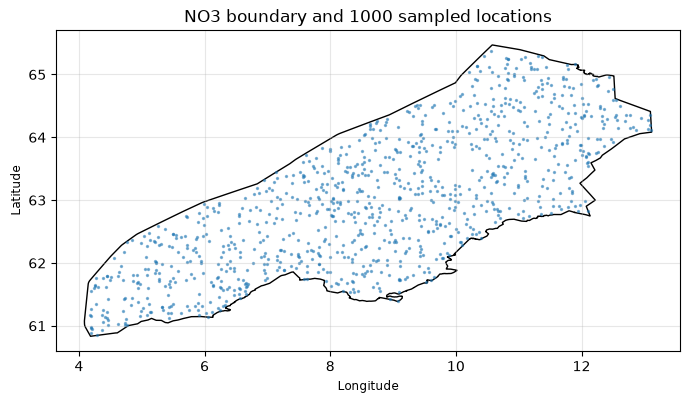

In [20]:
# Show the NO3 polygon and its sampled locations on a simple map.
no3_geometry = select_area_geometry(electricity_layer, "electricity", "NO3")
no3_points = sample_area_points(no3_geometry, count=POINTS_PER_REGION)

fig, ax = plt.subplots(figsize=(7, 8))
gpd.GeoSeries([no3_geometry], crs="EPSG:4326").plot(
    ax=ax, facecolor="none", edgecolor="black", linewidth=1.0
)
ax.scatter(no3_points["lon"], no3_points["lat"], s=2, alpha=0.5, color="tab:blue")
ax.set_title(f"NO3 boundary and {len(no3_points)} sampled locations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
fig.tight_layout()

## 5. ERA5 reanalysis for NO3, 2024

`download_region_weather(region_id, start_date, end_date)` is the assignment's
API function: it looks up the sampled coordinates for the region and downloads
hourly ERA5 temperature and precipitation from open-meteo. With
`resolution="hourly"` it returns the hourly area means (8,784 rows for 2024);
the SPC/LOF sections later aggregate them to daily means (temperature mean,
precipitation sum). The function caches the sampled points and the series under
`data/cache`, with the point count and resolution in the filename.

The call below uses 1000 locations for NO3 for the whole of 2024. Open-meteo
weights requests by locations and time span, so the download is batched and
paced; the free tier allows 10,000 calls per day.

In [21]:
def _resample_hourly(frame: pd.DataFrame, rule: str) -> pd.DataFrame:
    """Reduce hourly values to a coarser rule, summing precipitation."""
    aggregation = {
        column: DAILY_AGGREGATION.get(column, "mean")
        for column in frame.columns
    }
    return frame.resample(rule).agg(aggregation)

In [22]:
def _request_with_retry(
    url: str,
    params: dict[str, Any],
    attempts: int = API_MAX_ATTEMPTS,
    backoff: float = API_BACKOFF_SECONDS,
) -> requests.Response:
    """
    GET a URL, retrying on rate limits and transient server errors.

    open-meteo weighs requests by ``locations x variables`` and answers 429
    when the per-minute budget is exceeded. The delay grows exponentially and
    honours ``Retry-After`` when the server sends it.
    """
    delay = backoff
    last_error: Exception | None = None

    for attempt in range(1, attempts + 1):
        try:
            response = requests.get(url, params=params, timeout=240)
            if response.status_code == 429 or response.status_code >= 500:
                retry_after = response.headers.get("Retry-After")
                wait = float(retry_after) if retry_after else delay
                print(
                    f"    HTTP {response.status_code}; waiting {wait:.0f}s "
                    f"before retry {attempt}/{attempts - 1}"
                )
                time.sleep(wait)
                delay *= 2
                last_error = requests.HTTPError(
                    f"{response.status_code} for {response.url}", response=response
                )
                continue
            response.raise_for_status()
            return response
        except requests.RequestException as error:  # network hiccups
            last_error = error
            print(f"    request failed ({error}); retrying in {delay:.0f}s")
            time.sleep(delay)
            delay *= 2

    raise RuntimeError(
        f"open-meteo request failed after {attempts} attempts: {last_error}"
    )

In [23]:
def fetch_era5(
    points: pd.DataFrame,
    start_date: str,
    end_date: str,
    variables: Sequence[str] = ERA5_VARIABLES,
    batch_size: int = API_BATCH_SIZE,
    pause: float = API_PAUSE_SECONDS,
    resample: str | None = "1D",
) -> pd.DataFrame:
    """
    Download ERA5 reanalysis for several locations.

    ``points`` must hold WGS84 ``lon``/``lat`` in EPSG:4326 — open-meteo takes
    coordinates in that CRS by definition, so do not hand it projected metres.
    open-meteo accepts comma-separated coordinates in one request and answers
    with a list (one object per location). The hourly response is reduced to
    daily values while downloading (``resample="1D"``) so that 1000 locations
    stay manageable; pass ``resample=None`` for the raw hourly data.

    Temperatures are averaged and precipitation is summed within each day.
    Returns ``timestamp``, ``lat``, ``lon`` plus one column per variable.
    """
    if points.empty:
        raise ValueError("points is empty")
    require_columns(points, ("lon", "lat"), "points")

    frames: list[pd.DataFrame] = []
    total = len(points)
    for begin in range(0, total, batch_size):
        batch = points.iloc[begin : begin + batch_size]
        params = {
            "latitude": ",".join(f"{value:.6f}" for value in batch["lat"]),
            "longitude": ",".join(f"{value:.6f}" for value in batch["lon"]),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ",".join(variables),
            "models": "era5",
            "timezone": "UTC",
        }
        response = _request_with_retry(ERA5_URL, params)
        payload = response.json()
        if isinstance(payload, dict):  # single-location responses are not lists
            payload = [payload]

        for item in payload:
            frame = pd.DataFrame(item["hourly"])
            frame["timestamp"] = pd.to_datetime(frame.pop("time"), utc=True)
            frame = frame.set_index("timestamp")
            if resample:
                frame = _resample_hourly(frame, resample)
            frame = frame.reset_index()
            frame["lat"] = float(item["latitude"])
            frame["lon"] = float(item["longitude"])
            frames.append(frame)

        done = min(begin + batch_size, total)
        print(f"  {done}/{total} locations downloaded")
        time.sleep(pause)

    weather = pd.concat(frames, ignore_index=True)
    return weather[["timestamp", "lat", "lon", *variables]]

In [24]:
def area_mean(weather: pd.DataFrame) -> pd.DataFrame:
    """
    Average the per-location series into one series for the whole area.

    Averaging the daily values over all sampled locations approximates the
    area mean; ``point_count`` records how many locations were available.
    """
    if weather.empty:
        raise ValueError("weather is empty")

    numeric = [
        column
        for column in weather.columns
        if column not in ("timestamp", "lat", "lon")
    ]
    grouped = weather.groupby("timestamp")[numeric]
    area = grouped.mean()
    area["point_count"] = grouped.size()
    area.index.name = "date"
    return area

In [25]:
def region_kind(region_id: str) -> str:
    """
    Infer the NVE layer kind from a region identifier.

    Electricity areas are ``NO1``..``NO5``; the grouped precipitation regions
    are ``East``, ``West`` and ``North``. Electricity codes are compared
    without spaces and case so ``"NO 3"`` and ``"no3"`` both work.
    """
    code = normalise_code(region_id)
    if code in {normalise_code(value) for value in ELECTRICITY_AREAS}:
        return "electricity"
    if region_id in PRECIPITATION_GROUPS:
        return "precipitation"
    raise KeyError(
        f"Unknown region {region_id!r}; use one of "
        f"{list(ELECTRICITY_AREAS)} or {list(PRECIPITATION_GROUPS)}"
    )

In [26]:
def weather_cache_name(
    kind: str,
    name: str,
    start_date: str,
    end_date: str,
    count: int,
    resolution: str = "daily",
) -> str:
    """
    Return the cache name for one area, interval and sampling density.

    ``count`` is part of the name on purpose: a cheap smoke test with 24
    locations must never be reused as the 1000-location production result.
    ``resolution`` is omitted for the original daily cache (so it keeps its
    name) and appended for hourly output. CDS caches are named by
    ``src.utils.era5_cache.cache_name`` instead, which always encodes the
    resolution and the source.
    """
    base = f"weather_{kind}_{name}_{start_date}_{end_date}_{count}"
    return base if resolution == "daily" else f"{base}_{resolution}"

In [27]:
def download_region_weather(
    region_id: str,
    start_date: str,
    end_date: str,
    kind: str | None = None,
    count: int = POINTS_PER_REGION,
    refresh: bool = REFRESH_WEATHER,
    resolution: str = "daily",
    source: str = "open-meteo",
) -> pd.DataFrame:
    """
    Download ERA5 reanalysis for one region and a date interval.

    This is the assignment's "function for the API download task": it takes a
    region identifier plus a time interval, looks up the sampled longitude and
    latitude pairs for that region and downloads at least temperature and
    precipitation.

    Parameters
    ----------
    region_id:
        ``NO1``..``NO5`` for electricity areas or ``East``/``West``/``North``
        for the grouped NVE precipitation regions.
    start_date, end_date:
        Inclusive ISO dates (``YYYY-MM-DD``).
    kind:
        Optional layer kind. Inferred from ``region_id`` when omitted.
    count:
        Number of sampled locations. Part of the cache key, so a smoke test
        can never be mistaken for the full-resolution download.
    refresh:
        Ignore the parquet caches and download again.
    resolution:
        ``"hourly"`` keeps the raw hourly area means; ``"daily"`` (default)
        aggregates temperature to a daily mean and precipitation to a daily
        sum for the existing SPC/LOF analysis.
    source:
        ``"open-meteo"`` (default) queries the archive API. ``"cds"`` reads the
        same values from the Copernicus Climate Data Store: one GRIB request
        per year for the whole country box, then the same per-point cell and
        elevation translation, rounded per point to the API's one decimal
        (parity mode). Measured 2024, NO3, 1 000 points: temperature within
        0.015 K, precipitation identical, so either source can be used for the
        analysis. CDS needs ``[cdsapi]`` in ``.secrets/secrets.toml``; the
        caches carry a ``_cds`` suffix and never overwrite an open-meteo one.

    Returns
    -------
    DataFrame indexed by ``timestamp`` (hourly) or ``date`` (daily) with one
    column per ERA5 variable and ``point_count``.
    """
    if resolution not in {"hourly", "daily"}:
        raise ValueError("resolution must be 'hourly' or 'daily'")
    if source not in {"open-meteo", "cds"}:
        raise ValueError("source must be 'open-meteo' or 'cds'")
    start = pd.Timestamp(start_date).date().isoformat()
    end = pd.Timestamp(end_date).date().isoformat()
    if pd.Timestamp(start) > pd.Timestamp(end):
        raise ValueError("start_date must not be after end_date")

    kind = kind or region_kind(region_id)
    if source == "cds":
        # The writer owns the CDS file name: it always encodes the resolution
        # and the ``_cds`` suffix, so a CDS cache can never shadow the
        # open-meteo one.
        from src.utils.era5_cache import cache_name as cds_cache_name

        cache = cache_path(cds_cache_name(kind, region_id, start, end, str(count), resolution))
    else:
        cache = cache_path(weather_cache_name(kind, region_id, start, end, count, resolution))
    time_column = "timestamp" if resolution == "hourly" else "date"
    if cache.exists() and not refresh:
        print(f"  using cache {cache.name}")
        frame = pd.read_parquet(cache)
        frame[time_column] = pd.to_datetime(frame[time_column])
        return frame.set_index(time_column)

    areas = download_area_layer(kind)
    geometry = select_area_geometry(areas, kind, region_id)

    points_cache = cache_path(area_sample_name(kind, region_id, count))
    if points_cache.exists() and not refresh:
        points = pd.read_parquet(points_cache)
        print(f"  using sampled locations {points_cache.name}")
    else:
        points = sample_area_points(geometry, count=count)
        points.to_parquet(points_cache, index=False)
        print(f"  sampled {len(points)} locations -> {points_cache.name}")

    if source == "cds":
        # One GRIB request per year for the documented country box (the box the
        # parity was measured on), then the same per-point translation as the
        # API, rounded per point. Imported here so the notebook's open-meteo
        # path keeps working without eccodes/cdsapi installed.
        from src.utils.cds_era5 import DEFAULT_AREA
        from src.utils.era5_cache import build_area_cache

        path = build_area_cache(
            kind,
            region_id,
            start,
            end,
            mode="points",
            points=points,
            parity=True,
            resolution=resolution,
            area=list(DEFAULT_AREA),
            overwrite=refresh,
        )
        frame = pd.read_parquet(path)
        frame[time_column] = pd.to_datetime(frame[time_column])
        print(f"  using CDS cache {path.name}")
        return frame.set_index(time_column)

    weather = fetch_era5(
        points,
        start_date=start,
        end_date=end,
        resample=None if resolution == "hourly" else "1D",
    )
    area = area_mean(weather)
    if resolution == "hourly":
        area.index.name = "timestamp"
    area.reset_index().to_parquet(cache, index=False)
    print(f"  wrote cache {cache.name} ({len(area):,} rows)")
    return area

In [28]:
# Apply the download function to NO3 for 2024 with the full 1000 locations.
# resolution="hourly" keeps the raw hourly area means required by the task.
# The first run makes about 125 batched requests; later runs read the cache.
hourly_no3 = download_region_weather(
    "NO3",
    "2024-01-01",
    "2024-12-31",
    count=POINTS_PER_REGION,
    resolution="hourly",
)
display(hourly_no3.head())
print(f"Hourly rows: {len(hourly_no3):,}")
print(f"Locations per hour: {sorted(hourly_no3['point_count'].unique())}")

# Daily means for the precipitation, SPC and LOF sections below.
daily_no3 = hourly_no3.resample("1D").agg(
    {"temperature_2m": "mean", "precipitation": "sum", "point_count": "mean"}
)
daily_no3.index.name = "date"
print(f"Daily rows: {len(daily_no3)}")
display(daily_no3[["temperature_2m", "precipitation"]].describe())

  using cache weather_electricity_NO3_2024-01-01_2024-12-31_1000_hourly.parquet


,temperature_2m,precipitation,point_count
timestamp,,,
2024-01-01 00:00:00+00:00,-3.7461,0.0038,1000
2024-01-01 01:00:00+00:00,-3.8866,0.0030,1000
2024-01-01 02:00:00+00:00,-3.8660,0.0030,1000
2024-01-01 03:00:00+00:00,-3.9031,0.0030,1000
2024-01-01 04:00:00+00:00,-3.8498,0.0026,1000


Hourly rows: 8,784
Locations per hour: [np.int64(1000)]
Daily rows: 366


,temperature_2m,precipitation
count,366.000000,366.000000
mean,5.645633,4.942826
std,6.496519,5.293297
min,-10.962533,0.000000
25%,1.408005,0.791250
50%,5.654931,3.226650
75%,11.246911,7.112175
max,18.978429,29.900600


## 6. Average precipitation and SPC outliers

The first plot is the daily area-mean precipitation required by the
assignment. The assignment text names precipitation for the DCT/SPC step; the
teacher's clarification names temperature. Both series are therefore analysed
with the same function, precipitation first, so neither reading is lost.

The DCT high-pass removes the low-frequency seasonal part to form the
seasonally adjusted variations (SATV). The control limits are

    baseline + median(SATV) ± k · σ_robust(SATV)

where `baseline` is the low-pass part of the series and `σ_robust` is the
MAD-based standard deviation of the SATV. The default cut-off is 12 cycles/year
(about one month) and the default width is ±3σ, the conventional SPC control
limit; the ±2σ sensitivity is reported below. Only the observed series, the
baseline and the limits are plotted; the SATV is used only to find the
boundaries and the outliers.

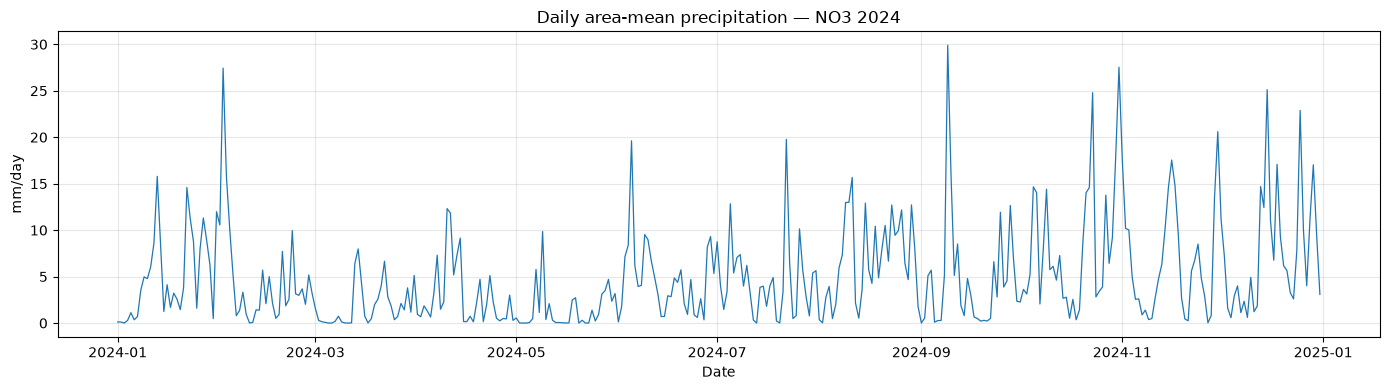

In [29]:
# Average precipitation as a function of time (required by the assignment).
precip = daily_no3["precipitation"]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(precip.index, precip, linewidth=0.9, color="tab:blue")
ax.set_title("Daily area-mean precipitation — NO3 2024")
ax.set_xlabel("Date")
ax.set_ylabel("mm/day")
ax.grid(True, alpha=0.3)
fig.tight_layout()

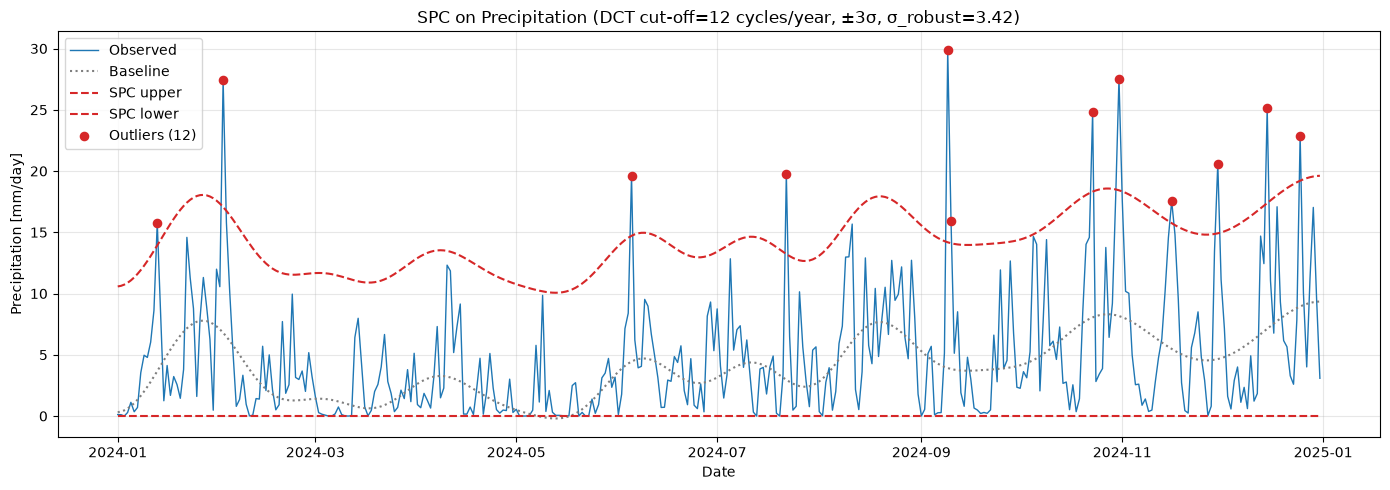

,value,satv,lower,upper
timestamp,,,,
2024-01-13 00:00:00+00:00,15.7902,11.244263,0.0,13.927615
2024-02-02 00:00:00+00:00,27.4408,19.756356,0.0,17.066122
2024-06-05 00:00:00+00:00,19.6165,14.285561,0.0,14.712616
2024-07-22 00:00:00+00:00,19.7700,15.928679,0.0,13.222998
2024-09-09 00:00:00+00:00,29.9006,25.098643,0.0,14.183635
2024-09-10 00:00:00+00:00,15.9563,11.230740,0.0,14.107238
2024-10-23 00:00:00+00:00,24.7915,15.856539,0.0,18.316639
2024-10-31 00:00:00+00:00,27.5316,18.484976,0.0,18.428302
2024-11-16 00:00:00+00:00,17.5446,11.184353,0.0,15.741924


SPC flagged 12 of 366 days (3.3%) at ±3σ.


In [30]:
# SPC on the daily area-mean precipitation (the series named by the task).
precip_fig, precip_summary, precip_outliers = spc_outliers(
    precip,
    cutoff_per_year=SPC_CUTOFF_CYCLES_PER_YEAR,
    n_std=SPC_STD_DEVIATIONS,
    label="Precipitation",
    unit="mm/day",
    lower_bound=0.0,  # precipitation cannot be negative
)
display(precip_fig)
plt.close(precip_fig)
display(precip_outliers.head(10))
print(
    f"SPC flagged {precip_summary['outliers']} of {precip_summary['hours']} days "
    f"({precip_summary['share']:.1%}) at ±{precip_summary['n_std']:g}σ."
)

**Findings.** At ±3σ and a 12-cycle/year cut-off, 12 precipitation days are
flagged, clustered in heavy-rain events through the year; at ±2σ the count is
39. The lower limit is floored at 0, so only the upper limit can be crossed.

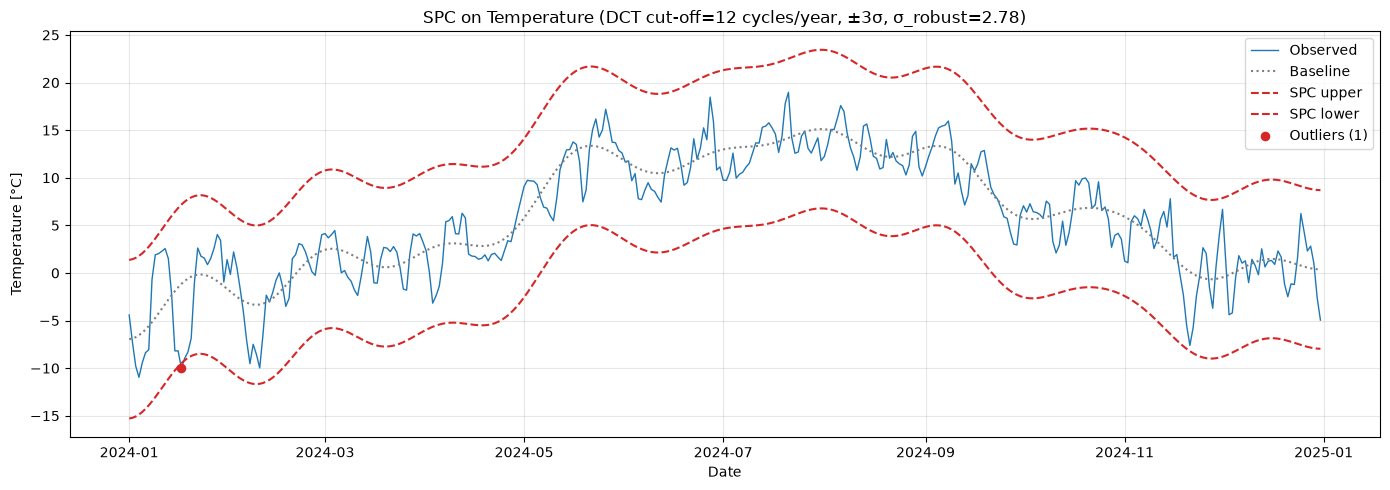

,value,satv,lower,upper
timestamp,,,,
2024-01-17 00:00:00+00:00,-10.03025,-8.675941,-9.483836,7.177071


SPC flagged 1 of 366 days (0.3%) at ±3σ.


In [31]:
# SPC on the daily area-mean temperature (the series named by the clarification).
# The SATV is used to derive the limits and the flags; it is not plotted.
temperature = daily_no3["temperature_2m"].copy()
temperature.name = "temperature_2m (NO3)"

temp_fig, temp_summary, temp_outliers = spc_outliers(
    temperature,
    cutoff_per_year=SPC_CUTOFF_CYCLES_PER_YEAR,
    n_std=SPC_STD_DEVIATIONS,
    label="Temperature",
    unit="°C",
)
display(temp_fig)
plt.close(temp_fig)
display(temp_outliers)
print(
    f"SPC flagged {temp_summary['outliers']} of {temp_summary['hours']} days "
    f"({temp_summary['share']:.1%}) at ±{temp_summary['n_std']:g}σ."
)

**Findings.** At the same 12 cycles/year and ±3σ, only 17 January exceeds the
limits; at ±2σ twenty days do. The 3σ day is a real cold day rather than a
data error, which is why the plot flags it without calling it wrong.

## 7. Local Outlier Factor anomalies

LOF compares the local density around each day with the density of its
neighbours. Each day is described by its time and its temperature, both
standardised, so a day is anomalous when its temperature does not fit the days
around it. `contamination=0.01` asks for about 1% of the days to be labelled
anomalous, as required by the assignment. The returned table contains the
flagged values and their LOF scores (higher means more anomalous).

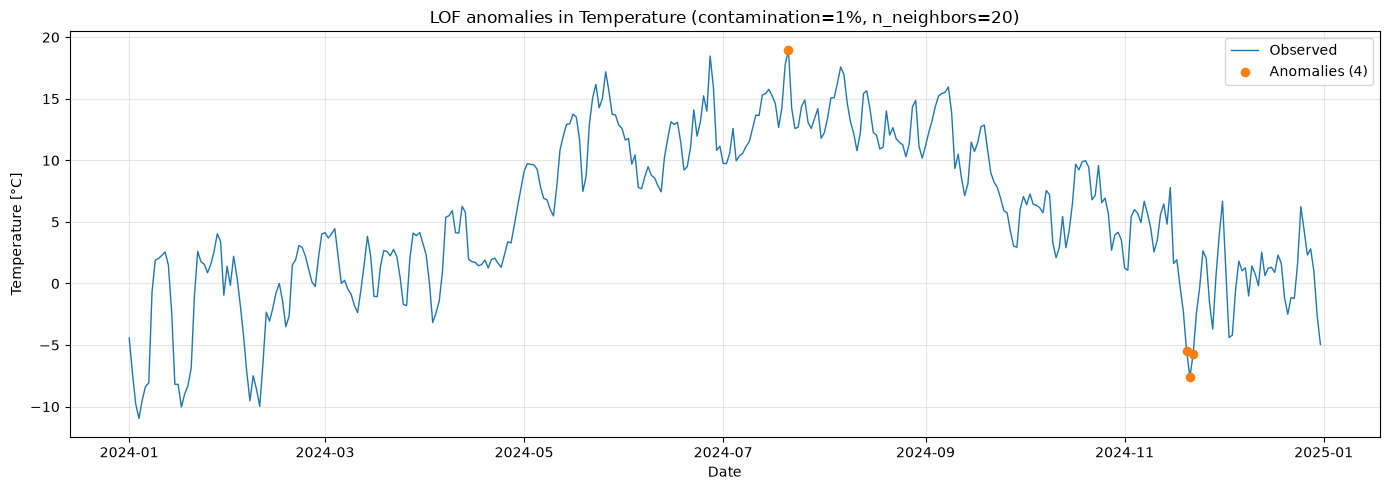

,value,lof_score
timestamp,,
2024-11-21 00:00:00+00:00,-7.607512,2.136370
2024-07-21 00:00:00+00:00,18.978429,1.755535
2024-11-22 00:00:00+00:00,-5.732388,1.720730
2024-11-20 00:00:00+00:00,-5.499029,1.684861


LOF flagged 4 of 366 days (1.1%).


In [32]:
# LOF on the same temperature series, with the required 1% contamination.
lof_fig, lof_summary, lof_table = lof_outliers(
    temperature,
    contamination=LOF_CONTAMINATION,
    n_neighbors=20,
    label="Temperature",
    unit="°C",
)
display(lof_fig)
plt.close(lof_fig)
display(lof_table)
print(
    f"LOF flagged {lof_summary['anomalies']} of {lof_summary['hours']} days "
    f"({lof_summary['share']:.1%})."
)

**Findings.** The four flagged days are 20–22 November, a cold spell, and
21 July. A value-only LOF would instead pick the hottest summer days; adding
time as a feature is what makes the method local.

## 8. Tests

The four analysis functions are tested on synthetic series where the correct
answer is known: STL must reconstruct the observed series, the spectrogram
must return consistent shapes, SPC must flag an injected spike, and LOF must
return about the requested proportion. The full self-test module adds scale
invariance, limit-centre, known-frequency and robust-effect checks; it is run
at the end.

In [33]:
# Test 1: STL must reconstruct the observed series.
test_index = pd.date_range("2020-01-06", periods=260, freq="W-MON")
test_values = (
    60
    + 10 * np.sin(2 * np.pi * np.arange(260) / 52)
    + np.random.default_rng(0).normal(0, 2, 260)
)
test_series = pd.Series(test_values, index=test_index, name="synthetic")
test_fig, test_result = stl_analysis(test_series)
assert np.allclose(test_result.trend + test_result.seasonal + test_result.resid, test_values)
print("STL test passed: trend + seasonal + residual equals the observed series.")
plt.close(test_fig)

STL test passed: trend + seasonal + residual equals the observed series.


In [34]:
# Test 2: the spectrogram must return one power value per frequency/segment.
test_fig, test_freqs, test_times, test_power = spectrogram_analysis(test_series)
assert test_power.shape == (test_freqs.size, test_times.size)
assert np.all(test_power >= 0)
print(f"Spectrogram test passed: {test_power.shape[0]} frequencies x "
      f"{test_power.shape[1]} segments.")
plt.close(test_fig)

Spectrogram test passed: 27 frequencies x 9 segments.


In [35]:
# Test 3: SPC must flag an injected spike.
spike_values = np.random.default_rng(0).normal(0, 1, 366)
spike_values[100] += 15
spike_series = pd.Series(
    spike_values,
    index=pd.date_range("2024-01-01", periods=366, freq="D"),
    name="spike",
)
spike_fig, spike_summary, spike_outliers = spc_outliers(
    spike_series, cutoff_per_year=12, n_std=3.0
)
assert spike_series.index[100] in spike_outliers.index
print("SPC test passed: the injected spike was flagged.")
plt.close(spike_fig)

SPC test passed: the injected spike was flagged.


In [36]:
# Test 4: LOF must return about the requested contamination proportion.
lof_values = np.random.default_rng(1).normal(0, 1, 200)
lof_series = pd.Series(
    lof_values,
    index=pd.date_range("2024-01-01", periods=200, freq="D"),
    name="lof_test",
)
lof_fig, lof_summary, lof_test = lof_outliers(lof_series, contamination=0.05)
assert 8 <= len(lof_test) <= 12
print(f"LOF test passed: {len(lof_test)} of 200 points flagged at 5% contamination.")
plt.close(lof_fig)

LOF test passed: 10 of 200 points flagged at 5% contamination.


In [37]:
# Run the complete test suite as a final check. The tests live in ``tests/`` and
# import this file's helpers through a fixture that skips the run cells above.
import subprocess
import sys

test_result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests"],
    cwd=REPO_ROOT,
    capture_output=True,
    text=True,
)
print(test_result.stdout.strip()[-2000:])
assert test_result.returncode == 0, "pytest failed; see the output above"

....................................                                     [100%]
36 passed in 1.66s


## 9. Summary

- The weekly filling series has 1,661 observations from 1995 to 2026. STL
  separates a slowly varying trend from a stable annual cycle; the residual
  contains the unusual weeks.
- The spectrogram shows a persistent annual band at about 0.019 cycles/week
  and a weaker semi-annual band. The zoomed frequency axis makes the
  low-frequency structure visible.
- The NVE Atlas layers match the Magasinstatistikk areas: five electricity
  areas and the five NVE regions grouped into East, West and North.
- The ERA5 download for NO3 2024 returns 8,784 hourly area means from 1000
  sampled locations; the analysis aggregates them to 366 daily means.
- The SPC analysis flags 12 precipitation days and 1 temperature day in 2024 at
  ±3σ with a 12-cycle/year cut-off; at ±2σ the counts are 39 and 20. LOF flags
  4 days at 1% contamination. All are shown in contrasting colours.
- The DCT/SPC step shows both series: precipitation follows the task text,
  temperature the teacher's clarification.
- The Streamlit app uses a different, land-clipped 100-cell hourly series, so
  its SPC/LOF counts are not expected to match these daily 1000-point numbers.

## Data sources

- **Magasinstatistikk:** <https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData>
- **Electricity areas:** NVE `Budomraade`, `https://kart.nve.no/enterprise/rest/services/Nettomraader/MapServer/0`; shapefile download in `data/shapefiles/atlas_nve/Budområder/`
- **Precipitation areas:** NVE `NVE_Region`, `https://kart.nve.no/enterprise/rest/services/Mapservices/Administrasjon2/MapServer/0`; shapefile download in `data/shapefiles/atlas_nve/NVE_Region/`
- **ERA5:** <https://open-meteo.com/en/docs>, `https://archive-api.open-meteo.com/v1/archive`
- **NVE Atlas:** <https://atlas.nve.no>

All data are cached locally under `data/cache`; the cache files are gitignored
and can be rebuilt by re-running the notebook with the `REFRESH_*` flags set
to `True`.